In [ ]:
import requests
from urllib.parse import urljoin
from io import BytesIO, StringIO
import pandas as pd
import numpy as np
import re
from typing import Dict

BASE_SEARCH = "https://wwwn.cdc.gov"
HEADERS = {"User-Agent": "Mozilla/5.0"}
CYCLES = {
    2013: "2013-2014",
    2015: "2015-2016",
    2017: "2017-2018"
}
TIMEOUT = 45

session = requests.Session()
session.headers.update(HEADERS)

def get_file_urls(component: str, start_year: int) -> Dict[str, str]:
    """Scrape NHANES search page and return XPT URLs"""
    url = (
        f"{BASE_SEARCH}/nchs/nhanes/search/datapage.aspx"
        f"?Component={component}&CycleBeginYear={start_year}"
    )
    try:
        r = session.get(url, timeout=TIMEOUT)
        r.raise_for_status()
    except Exception:
        return {}

    links = {}
    for m in re.finditer(r'href=["\\]([^"\\]+\.XPT)["\\]', r.text, re.I):
        absurl = urljoin(BASE_SEARCH, m.group(1))
        fname = absurl.split("/")[-1].upper()
        links[fname] = absurl
    return links


def download_xpt(url: str) -> pd.DataFrame | None:
    """Download and read an XPT file"""
    try:
        r = session.get(url, timeout=TIMEOUT)
        r.raise_for_status()
        df = pd.read_sas(BytesIO(r.content), format="xport")
        df.columns = df.columns.str.upper()
        return df
    except Exception:
        return None


print("\nStarting CKD Graph Network Data Retrieval\n")

masters = []

for start_year, cycle_name in CYCLES.items():
    print(f"Processing NHANES {cycle_name}")

    # ---------------- DEMOGRAPHICS ----------------
    demo_links = get_file_urls("Demographics", start_year)
    demo_url = next(u for k, u in demo_links.items() if "DEMO" in k)

    demo_df = download_xpt(demo_url)
    demo_df["SEQN"] = demo_df["SEQN"].astype(int)

    # Keep survey design variables + MEC weight
    keep_demo_cols = [
        "SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH3",
        "SDMVSTRA", "SDMVPSU", "WTMEC2YR","RIDEXPRG"
    ]
    master = demo_df[[c for c in keep_demo_cols if c in demo_df.columns]].copy()

    # ---------------- EXAMINATION (Added for BMI) ----------------
    exam_links = get_file_urls("Examination", start_year)
    bmx_matches = [u for k, u in exam_links.items() if "BMX" in k]
    if bmx_matches:
        exam_df = download_xpt(bmx_matches[0])
        if exam_df is not None and "SEQN" in exam_df.columns:
            exam_df["SEQN"] = exam_df["SEQN"].astype(int)
            # Keep only SEQN and BMXBMI (Body Mass Index)
            keep_exam_cols = ["SEQN", "BMXBMI"]
            exam_subset = exam_df[[c for c in keep_exam_cols if c in exam_df.columns]].copy()
            master = master.merge(exam_subset, on="SEQN", how="left")
            print("  ✓ BMX (BMI)")

    # ---------------- LAB FILES ----------------
    lab_links = get_file_urls("Laboratory", start_year)

    # Added "CRP" and "HSCRP" explicitly to the prefix matching pipeline
    lab_prefixes = [
        "BIOPRO", "ALB_CR", "FERTIN","FERITIN", "CBC", "GHB", "GLU",
        "TCHOL", "HDL", "TRIGLY", "CRP", "HSCRP",
        "FOLATE", "VITB12", "PTH", "VID", "HOMOCY",
        "THYROD", "INS"
    ]

    for prefix in lab_prefixes:
        matches = [u for k, u in lab_links.items() if prefix in k]
        if not matches:
            continue

        lab_df = download_xpt(matches[0])
        if lab_df is None or "SEQN" not in lab_df:
            continue

        lab_df["SEQN"] = lab_df["SEQN"].astype(int)
        master = master.merge(lab_df, on="SEQN", how="left", suffixes=("", "_DROP"))
        master = master.loc[:, ~master.columns.str.endswith("_DROP")]

        print(f"  ✓ {prefix}")

    # Create 6-year weight for combined 2013-2018 analysis
    if "WTMEC2YR" in master.columns:
        master["WTMEC6YR"] = pd.to_numeric(master["WTMEC2YR"], errors="coerce") / 3.0

    master["CYCLE"] = cycle_name
    masters.append(master)

final_df = pd.concat(masters, ignore_index=True, sort=False)

print("\n" + "=" * 60)
print("MORTALITY LINKAGE")
print("=" * 60)

MORTALITY_URLS = {
    2013: "https://ftp.cdc.gov/pub/Health_Statistics/NCHS/datalinkage/linked_mortality/NHANES_2013_2014_MORT_2019_PUBLIC.dat",
    2015: "https://ftp.cdc.gov/pub/Health_Statistics/NCHS/datalinkage/linked_mortality/NHANES_2015_2016_MORT_2019_PUBLIC.dat",
    2017: "https://ftp.cdc.gov/pub/Health_Statistics/NCHS/datalinkage/linked_mortality/NHANES_2017_2018_MORT_2019_PUBLIC.dat",
}

mortality_all = []

for year, url in MORTALITY_URLS.items():
    try:
        r = session.get(url, timeout=60)
        r.raise_for_status()
        mort = pd.read_fwf(
           StringIO(r.text),
           colspecs=[
              (0, 6),    # SEQN
              (14, 15),  # ELIGSTAT
              (15, 16),  # MORTSTAT
              (42, 44),  # PERMTH_INT
              (45, 47),  # PERMTH_EXM
            ],
            names=[
                "SEQN",
                "ELIGSTAT",
                "MORTSTAT",
                "PERMTH_INT",
                "PERMTH_EXM"
            ],
            dtype=str
        )

        mort["SEQN"] = mort["SEQN"].str.strip().astype(int)

        mort["MORTSTAT"] = pd.to_numeric(
            mort["MORTSTAT"],
            errors="coerce"
        )

        mort["PERMTH_INT"] = pd.to_numeric(
            mort["PERMTH_INT"].str.strip(),
            errors="coerce"
        )

        mort["PERMTH_EXM"] = pd.to_numeric(
            mort["PERMTH_EXM"].str.strip(),
            errors="coerce"
        )

        mortality_all.append(mort)

        print(
            f"✓ {CYCLES[year]}: "
            f"{mort['MORTSTAT'].sum():.0f} deaths / {len(mort):,} records"
        )

    except Exception as e:
        print(f"✗ {CYCLES[year]} failed: {e}")

mortality = pd.concat(mortality_all, ignore_index=True)

final_df = final_df.merge(
    mortality[["SEQN", "MORTSTAT", "PERMTH_EXM", "PERMTH_INT"]],
    on="SEQN",
    how="left"
)

print(f"\n✓ Total linked deaths: {final_df['MORTSTAT'].sum():.0f}")

print("\n" + "=" * 60)
print("CLEANING BIOMARKER DUPLICATES")
print("=" * 60)

drop_cols = [c for c in final_df.columns if c.endswith("SI") or c.endswith("LC")]
final_df.drop(columns=drop_cols, inplace=True)

print(f"Dropped {len(drop_cols)} metadata columns")

final_df.to_csv("NHANES_CKD_GRAPH.csv", index=False)

print("\n" + "=" * 60)
print("FINAL CKD GRAPH DATASET READY")
print("=" * 60)
print(f"Rows:    {len(final_df):,}")
print(f"Columns: {len(final_df.columns)}")
print("✓ Saved: NHANES_CKD_GRAPH.csv")
print("✓ Survey weights included: WTMEC2YR, WTMEC6YR")
print("✓ Design variables included: SDMVSTRA, SDMVPSU")
print("✓ Mortality linkage validated")
print("✓ Ready for CKD graph-theoretic analysis\n")


Starting CKD Graph Network Data Retrieval

Processing NHANES 2013-2014
  ✓ BMX (BMI)
  ✓ BIOPRO
  ✓ ALB_CR
  ✓ CBC
  ✓ GHB
  ✓ GLU
  ✓ TCHOL
  ✓ HDL
  ✓ TRIGLY
  ✓ FOLATE
  ✓ VITB12
  ✓ VID
  ✓ INS
Processing NHANES 2015-2016
  ✓ BMX (BMI)
  ✓ BIOPRO
  ✓ ALB_CR
  ✓ FERTIN
  ✓ CBC
  ✓ GHB
  ✓ GLU
  ✓ TCHOL
  ✓ HDL
  ✓ TRIGLY
  ✓ CRP
  ✓ HSCRP
  ✓ FOLATE
  ✓ VID
  ✓ INS
Processing NHANES 2017-2018
  ✓ BMX (BMI)
  ✓ BIOPRO
  ✓ ALB_CR
  ✓ FERTIN
  ✓ CBC
  ✓ GHB
  ✓ GLU
  ✓ TCHOL
  ✓ HDL
  ✓ TRIGLY
  ✓ CRP
  ✓ HSCRP
  ✓ FOLATE
  ✓ VID
  ✓ INS

MORTALITY LINKAGE
✓ 2013-2014: 467 deaths / 10,175 records
✓ 2015-2016: 276 deaths / 9,971 records
✓ 2017-2018: 145 deaths / 9,254 records

✓ Total linked deaths: 888

CLEANING BIOMARKER DUPLICATES
Dropped 51 metadata columns

FINAL CKD GRAPH DATASET READY
Rows:    29,400
Columns: 69
✓ Saved: NHANES_CKD_GRAPH.csv
✓ Survey weights included: WTMEC2YR, WTMEC6YR
✓ Design variables included: SDMVSTRA, SDMVPSU
✓ Mortality linkage validated
✓ Ready for CKD 

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("NHANES_CKD_GRAPH.csv")
n_raw = len(df)

# ── STEP 1: Age ≥ 18 ──────────────────────────────────────────
df = df[df["RIDAGEYR"] >= 18].copy()
n_adult = len(df)

# ── STEP 2: Remove pregnant ────────────────────────────────────
# RIDEXPRG: 1=pregnant, 2=not pregnant, 3=indeterminate, NaN=male/not asked
n_before_preg = len(df)
df = df[df["RIDEXPRG"] != 1].copy()
n_after_preg = len(df)

# ── STEP 3: Compute eGFR (CKD-EPI 2021) ───────────────────────
def compute_egfr_2021(df):
    scr   = df["LBXSCR"]
    age   = df["RIDAGEYR"]
    female = df["RIAGENDR"] == 2
    kappa = np.where(female, 0.7, 0.9)
    alpha = np.where(female, -0.241, -0.302)
    scr_k = scr / kappa
    egfr  = (
        142
        * np.minimum(scr_k, 1) ** alpha
        * np.maximum(scr_k, 1) ** -1.200
        * (0.9938 ** age)
        * np.where(female, 1.012, 1.0)
    )
    return egfr

df["EGFR"] = compute_egfr_2021(df)
n_before_egfr = len(df)
df = df[df["EGFR"].notna()].copy()
n_after_egfr = len(df)

# ── STEP 4: Drop sparse columns (<20% complete) ───────────────
min_non_missing = 0.20 * len(df)
keep_cols = [
    c for c in df.columns
    if df[c].notna().sum() >= min_non_missing or c == "MORTSTAT"
]
n_cols_before = len(df.columns)
df = df[keep_cols].copy()
n_cols_after = len(df.columns)

# ── SAVE ──────────────────────────────────────────────────────
df.to_csv("NHANES_CKD_GRAPH.csv", index=False)

# ── PATIENT FLOW ──────────────────────────────────────────────
print("=" * 55)
print("         PATIENT FLOW SUMMARY")
print("=" * 55)
print(f"  Raw NHANES 2013-2018 linked          {n_raw:>7,}")
print(f"  ── remove age < 18            -{n_raw - n_adult:>6,}  → {n_adult:,}")
print(f"  ── remove pregnant (RIDEXPRG=1) -{n_before_preg - n_after_preg:>4,}  → {n_after_preg:,}")
print(f"  ── remove missing creatinine   -{n_before_egfr - n_after_egfr:>4,}  → {n_after_egfr:,}")
print("-" * 55)
print(f"  FINAL ANALYTIC SAMPLE                {n_after_egfr:>7,}")
print(f"  Deaths (MORTSTAT=1)                  {int(df['MORTSTAT'].sum()):>7,}")
print(f"  CKD (eGFR < 60)                      {(df['EGFR'] < 60).sum():>7,}")
print(f"  Healthy (eGFR ≥ 60)                  {(df['EGFR'] >= 60).sum():>7,}")
print("-" * 55)
print(f"  Columns kept (≥20% complete)         {n_cols_after:>7,}  (dropped {n_cols_before - n_cols_after})")
print("=" * 55)

         PATIENT FLOW SUMMARY
  Raw NHANES 2013-2018 linked           29,400
  ── remove age < 18            -11,439  → 17,961
  ── remove pregnant (RIDEXPRG=1) - 190  → 17,771
  ── remove missing creatinine   -1,776  → 15,995
-------------------------------------------------------
  FINAL ANALYTIC SAMPLE                 15,995
  Deaths (MORTSTAT=1)                      749
  CKD (eGFR < 60)                        1,251
  Healthy (eGFR ≥ 60)                   14,744
-------------------------------------------------------
  Columns kept (≥20% complete)              65  (dropped 5)


In [ ]:
names(df)
grep("HGB|HEMO|HB", names(df), value = TRUE)

In [ ]:
install.packages("survey")
install.packages("dplyr")

In [ ]:
# Install once
library(survey)
library(dplyr)

df <- read.csv("NHANES_CKD_GRAPH.csv")

# -------- SAFE CRP ALIGNMENT (Base R approach to bypass dplyr strict type-checking) --------
if ("LBXCRP" %in% names(df)) {
  df$CRP_VAL <- df$LBXCRP
} else if ("LBXHSCRP" %in% names(df)) {
  df$CRP_VAL <- df$LBXHSCRP
} else {
  df$CRP_VAL <- NA_real_
}

# ---------------- DEFINE VARIABLES ----------------
df <- df %>%
  mutate(
    # Anemia
    ANEMIA = ifelse(
      (RIAGENDR == 1 & LBXHGB < 13) |
      (RIAGENDR == 2 & LBXHGB < 12),
      1, 0
    ),

    # eGFR strata
    EGFR_GROUP = ifelse(EGFR < 60, "Low eGFR", "High eGFR"),

    # Age groups
    AGE_GROUP = case_when(
      RIDAGEYR >= 18 & RIDAGEYR < 40 ~ "18-40",
      RIDAGEYR >= 40 & RIDAGEYR < 60 ~ "40-60",
      RIDAGEYR >= 60 ~ ">=60"
    ),

    # Sex
    SEX = ifelse(RIAGENDR == 1, "Men", "Women"),

    # Race
    RACE = case_when(
      RIDRETH3 == 1 ~ "Mexican American",
      RIDRETH3 == 2 ~ "Other Hispanic",
      RIDRETH3 == 3 ~ "NH White",
      RIDRETH3 == 4 ~ "NH Black",
      RIDRETH3 == 6 ~ "NH Asian"
    ),

    # Diabetes
    DM = ifelse(LBXGH >= 6.5, 1, 0),
    DM_GROUP = case_when(
      RIAGENDR == 1 & DM == 0 ~ "Male, No DM",
      RIAGENDR == 1 & DM == 1 ~ "Male, Diabetes",
      RIAGENDR == 2 & DM == 0 ~ "Female, No DM",
      RIAGENDR == 2 & DM == 1 ~ "Female, Diabetes"
    ),

    # -------- CRP PROCESSING --------
    CRP_HIGH = ifelse(CRP_VAL >= 3.0, 1, 0),
    CRP_GROUP = case_when(
      RIAGENDR == 1 & CRP_HIGH == 0 ~ "Male, Low CRP",
      RIAGENDR == 1 & CRP_HIGH == 1 ~ "Male, High CRP",
      RIAGENDR == 2 & CRP_HIGH == 0 ~ "Female, Low CRP",
      RIAGENDR == 2 & CRP_HIGH == 1 ~ "Female, High CRP"
    ),

    # -------- BMI (ENABLED) --------
    BMI_GROUP = case_when(
      RIAGENDR == 1 & BMXBMI < 25 ~ "Men (<25)",
      RIAGENDR == 1 & BMXBMI >= 25 & BMXBMI < 30 ~ "Men (25-30)",
      RIAGENDR == 1 & BMXBMI >= 30 ~ "Men (>=30)",
      RIAGENDR == 2 & BMXBMI < 25 ~ "Women (<25)",
      RIAGENDR == 2 & BMXBMI >= 25 & BMXBMI < 30 ~ "Women (25-30)",
      RIAGENDR == 2 & BMXBMI >= 30 ~ "Women (>=30)"
    )
  )

# ---------------- SURVEY DESIGN ----------------
design <- svydesign(
  id = ~SDMVPSU,
  strata = ~SDMVSTRA,
  weights = ~WTMEC6YR,
  data = df,
  nest = TRUE
)

# ---------------- FUNCTION ----------------
get_stratified <- function(varname, label) {

  formula_var = as.formula(paste0("~EGFR_GROUP + ", varname))

  prev <- svyby(
    ~ANEMIA,
    formula_var,
    design,
    svymean,
    na.rm = TRUE
  )

  counts <- df %>%
    group_by(EGFR_GROUP, .data[[varname]]) %>%
    summarise(N = n(), .groups = "drop")

  out <- merge(prev, counts, by.x = c("EGFR_GROUP", varname),
               by.y = c("EGFR_GROUP", varname))

  out <- out %>%
    mutate(
      Category = label,
      Subgroup = .data[[varname]],
      Prevalence = ANEMIA * 100,
      LowerCI = (ANEMIA - 1.96 * se) * 100,
      UpperCI = (ANEMIA + 1.96 * se) * 100
    ) %>%
    select(Category, Subgroup, EGFR_GROUP, N,
           Prevalence, LowerCI, UpperCI)

  return(out)
}
results <- bind_rows(
  get_stratified("SEX", "Sex"),
  get_stratified("AGE_GROUP", "Age"),
  get_stratified("RACE", "Race"),
  get_stratified("DM_GROUP", "Diabetes"),
  get_stratified("CRP_GROUP", "CRP"),
  get_stratified("BMI_GROUP", "BMI")
)

# ---------------- OUTPUT ----------------
results
write.csv(results, "anemia_by_egfr_stratified.csv", row.names = FALSE)

Category,Subgroup,EGFR_GROUP,N,Prevalence,LowerCI,UpperCI
<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
Sex,Men,High eGFR,7158,3.462414,2.905044,4.019784
Sex,Women,High eGFR,7586,8.830439,7.738925,9.921952
Sex,Men,Low eGFR,601,25.701598,21.291614,30.111582
Sex,Women,Low eGFR,650,23.729426,19.139402,28.319450
Age,>=60,High eGFR,4208,6.712608,5.767775,7.657440
Age,18-40,High eGFR,5593,5.520350,4.687058,6.353642
Age,40-60,High eGFR,4943,6.559029,5.430731,7.687326
Age,>=60,Low eGFR,1082,25.326718,21.396225,29.257211
Age,18-40,Low eGFR,26,16.927353,3.046432,30.808274



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggplot2 package.
  Please report the issue at <https://github.com/tidyverse/ggplot2/issues>.”
`height` was translated to `width`.


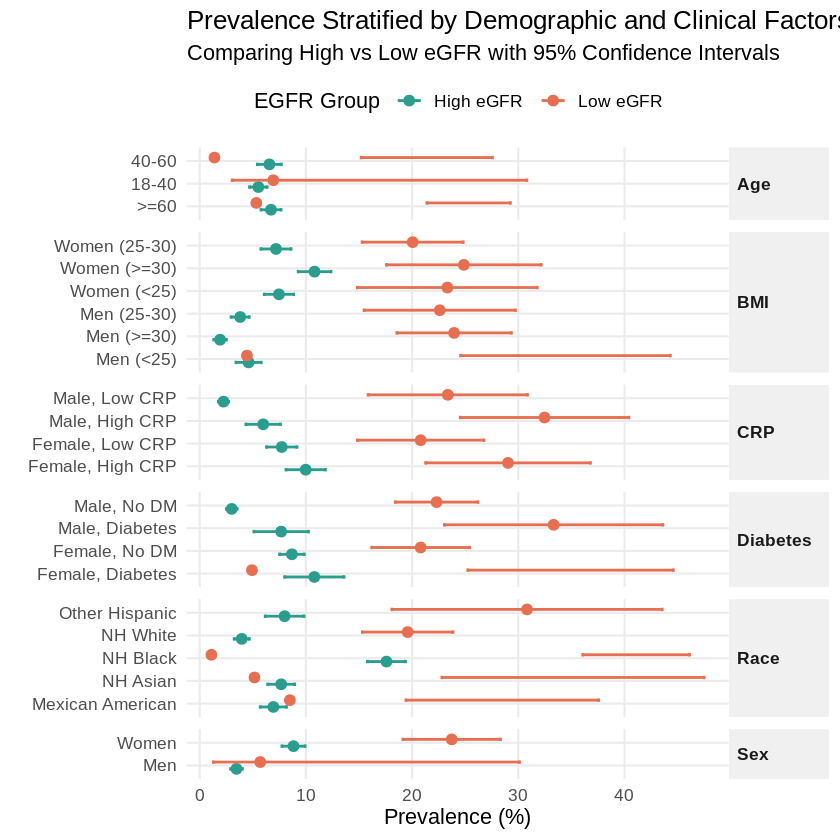

In [ ]:
library(ggplot2)
library(dplyr)

# 1. Read in your data
data <- read.table(text = "
Category Subgroup EGFR_GROUP N Prevalence LowerCI UpperCI
Sex Men 'High eGFR' 7158 3.462414 2.905044 4.019784
Sex Women 'High eGFR' 7586 8.830439 7.738925 9.921952
Sex Men 'Low eGFR' 6012 5.701598 1.291614 30.111582
Sex Women 'Low eGFR' 6502 23.729426 19.139402 28.319450
Age '>=60' 'High eGFR' 4208 6.712608 5.767775 7.657440
Age '18-40' 'High eGFR' 5593 5.520350 4.687058 6.353642
Age '40-60' 'High eGFR' 4943 6.559029 5.430731 7.687326
Age '>=60' 'Low eGFR' 10822 5.326718 21.396225 29.257211
Age '18-40' 'Low eGFR' 261 6.927353 3.046432 30.808274
Age '40-60' 'Low eGFR' 1432 1.384158 15.206733 27.561584
Race 'Mexican American' 'High eGFR' 2363 6.933978 5.697398 8.170559
Race 'NH Asian' 'High eGFR' 1914 7.668442 6.402174 8.934710
Race 'NH Black' 'High eGFR' 2929 17.583589 15.796482 19.370696
Race 'NH White' 'High eGFR' 5320 3.957079 3.243070 4.671089
Race 'Other Hispanic' 'High eGFR' 1608 7.993827 6.168394 9.819261
Race 'Mexican American' 'Low eGFR' 1092 8.489608 19.411137 37.568080
Race 'NH Asian' 'Low eGFR' 553 5.156702 22.808494 47.504909
Race 'NH Black' 'Low eGFR' 3964 1.097546 36.071357 46.123735
Race 'NH White' 'Low eGFR' 591 19.582368 15.320745 23.843991
Race 'Other Hispanic' 'Low eGFR' 70 30.821782 18.090260 43.553304
Diabetes 'Female, Diabetes' 'High eGFR' 780 10.792371 7.996280 13.588461
Diabetes 'Female, No DM' 'High eGFR' 6800 8.682327 7.518387 9.846267
Diabetes 'Male, Diabetes' 'High eGFR' 864 7.670051 5.097623 10.242480
Diabetes 'Male, No DM' 'High eGFR' 6290 3.014607 2.508717 3.520498
Diabetes 'Female, Diabetes' 'Low eGFR' 1643 4.920019 25.244493 44.595546
Diabetes 'Female, No DM' 'Low eGFR' 483 20.805624 16.203135 25.408113
Diabetes 'Male, Diabetes' 'Low eGFR' 193 33.327057 23.043707 43.610408
Diabetes 'Male, No DM' 'Low eGFR' 408 22.308646 18.418888 26.198404
CRP 'Female, High CRP' 'High eGFR' 2056 9.976779 8.123966 11.829591
CRP 'Female, Low CRP' 'High eGFR' 2856 7.722663 6.290661 9.154665
CRP 'Male, High CRP' 'High eGFR' 1372 5.974268 4.347664 7.600871
CRP 'Male, Low CRP' 'High eGFR' 3294 2.237945 1.753286 2.722603
CRP 'Female, High CRP' 'Low eGFR' 190 29.034679 21.274604 36.794753
CRP 'Female, Low CRP' 'Low eGFR' 231 20.808398 14.856041 26.760755
CRP 'Male, High CRP' 'Low eGFR' 188 32.472702 24.535442 40.409962
CRP 'Male, Low CRP' 'Low eGFR' 209 23.361125 15.859103 30.863147
BMI 'Men (<25)' 'High eGFR' 1997 4.599986 3.416454 5.783519
BMI 'Men (>=30)' 'High eGFR' 2478 1.917015 1.321008 2.513022
BMI 'Men (25-30)' 'High eGFR' 2590 3.810212 2.953671 4.666752
BMI 'Women (<25)' 'High eGFR' 2300 7.462809 6.079194 8.846424
BMI 'Women (>=30)' 'High eGFR' 3180 10.811221 9.269014 12.353427
BMI 'Women (25-30)' 'High eGFR' 2024 7.179372 5.755649 8.603095
BMI 'Men (<25)' 'Low eGFR' 1293 4.446174 24.571916 44.320432
BMI 'Men (>=30)' 'Low eGFR' 242 23.953336 18.556083 29.350589
BMI 'Men (25-30)' 'Low eGFR' 216 22.606281 15.485319 29.727243
BMI 'Women (<25)' 'Low eGFR' 131 23.320779 14.853458 31.788101
BMI 'Women (>=30)' 'Low eGFR' 309 24.870820 17.586416 32.155224
BMI 'Women (25-30)' 'Low eGFR' 190 20.049780 15.292675 24.806885
", header = TRUE)

# 2. Build the plot
ggplot(data, aes(x = Prevalence, y = Subgroup, color = EGFR_GROUP)) +
  # Adds the point for prevalence
  geom_point(position = position_dodge(width = 0.6), size = 2.5) +
  # Adds the horizontal error bars for CIs
  geom_errorbarh(aes(xmin = LowerCI, xmax = UpperCI),
                 position = position_dodge(width = 0.6), height = 0.3, size = 0.8) +
  # Separates the plot by Category (Sex, Age, Race, etc.)
  facet_grid(Category ~ ., scales = "free_y", space = "free_y") +
  # Cool minimalist medical-journal styling
  theme_minimal(base_size = 13) +
  labs(
    title = "Prevalence Stratified by Demographic and Clinical Factors",
    subtitle = "Comparing High vs Low eGFR with 95% Confidence Intervals",
    x = "Prevalence (%)",
    y = NULL,
    color = "EGFR Group"
  ) +
  scale_color_manual(values = c("High eGFR" = "#2a9d8f", "Low eGFR" = "#e76f51")) +
  theme(
    strip.text.y = element_text(angle = 0, face = "bold", hjust = 0), # Horizontal facet labels
    strip.background = element_rect(fill = "#f0f0f0", color = NA),
    panel.spacing = unit(0.5, "lines"),
    legend.position = "top",
    panel.grid.minor = element_blank()
  )

In [ ]:
install.packages("survey")
install.packages("dplyr")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message in install.packages("survey"):
“installation of package ‘survey’ had non-zero exit status”
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
install.packages("corrplot")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message in install.packages("corrplot"):
“installation of package ‘corrplot’ had non-zero exit status”


In [ ]:
install.packages("survey")
install.packages("corrplot")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
install.packages("gridExtra")

In [ ]:
# =====================================================
# SIMPLE SURVEY-WEIGHTED PEARSON CORRELATION TABLES
# =====================================================

library(survey)
library(dplyr)

# ---------------- LOAD DATA ----------------
df <- read.csv("NHANES_CKD_GRAPH.csv")

# ---------------- VARIABLES ----------------
target_vars <- c(
  "LBXSCR",
  "LBXSBU",
  "URDACT",
  "LBXHGB",
  "LBXHCT",
  "LBXMC",
  "LBXRDW",
  "LBXFER",
  "LBXHSCRP"
)

# Keep only variables that exist
vars <- intersect(target_vars, names(df))

cat("Variables being used:\n")
print(vars)

# ---------------- SURVEY DESIGN ----------------
design <- svydesign(
  id = ~SDMVPSU,
  strata = ~SDMVSTRA,
  weights = ~WTMEC6YR,
  data = df,
  nest = TRUE
)
design_low <- subset(design, EGFR < 60)
design_high <- subset(design, EGFR >= 60)
weighted_cor <- function(design_obj, vars) {

  n <- length(vars)

  out <- matrix(NA, n, n)

  rownames(out) <- vars
  colnames(out) <- vars

  for(i in 1:n) {

    for(j in 1:n) {

      if(i == j) {
        out[i,j] <- 1
        next
      }

      v1 <- vars[i]
      v2 <- vars[j]

      tmp <- tryCatch({

        cov_mat <- as.matrix(
          svyvar(
            as.formula(
              paste0("~", v1, " + ", v2)
            ),
            design_obj,
            na.rm = TRUE
          )
        )

        if(nrow(cov_mat) < 2) {
          return(NA)
        }

        cor_val <- cov_mat[1,2] /
          sqrt(cov_mat[1,1] * cov_mat[2,2])

        round(cor_val, 3)

      }, error = function(e) {
        NA
      })

      out[i,j] <- tmp
    }
  }

  return(as.data.frame(out))
}
cat("\nLOW eGFR correlations:\n")

cor_low <- weighted_cor(design_low, vars)

print(cor_low)

cat("\nHIGH eGFR correlations:\n")

cor_high <- weighted_cor(design_high, vars)

print(cor_high)
write.csv(
  cor_low,
  "weighted_cor_low_egfr.csv",
  row.names = TRUE
)

write.csv(
  cor_high,
  "weighted_cor_high_egfr.csv",
  row.names = TRUE
)

cat("\nFiles saved:\n")
cat("weighted_cor_low_egfr.csv\n")
cat("weighted_cor_high_egfr.csv\n")

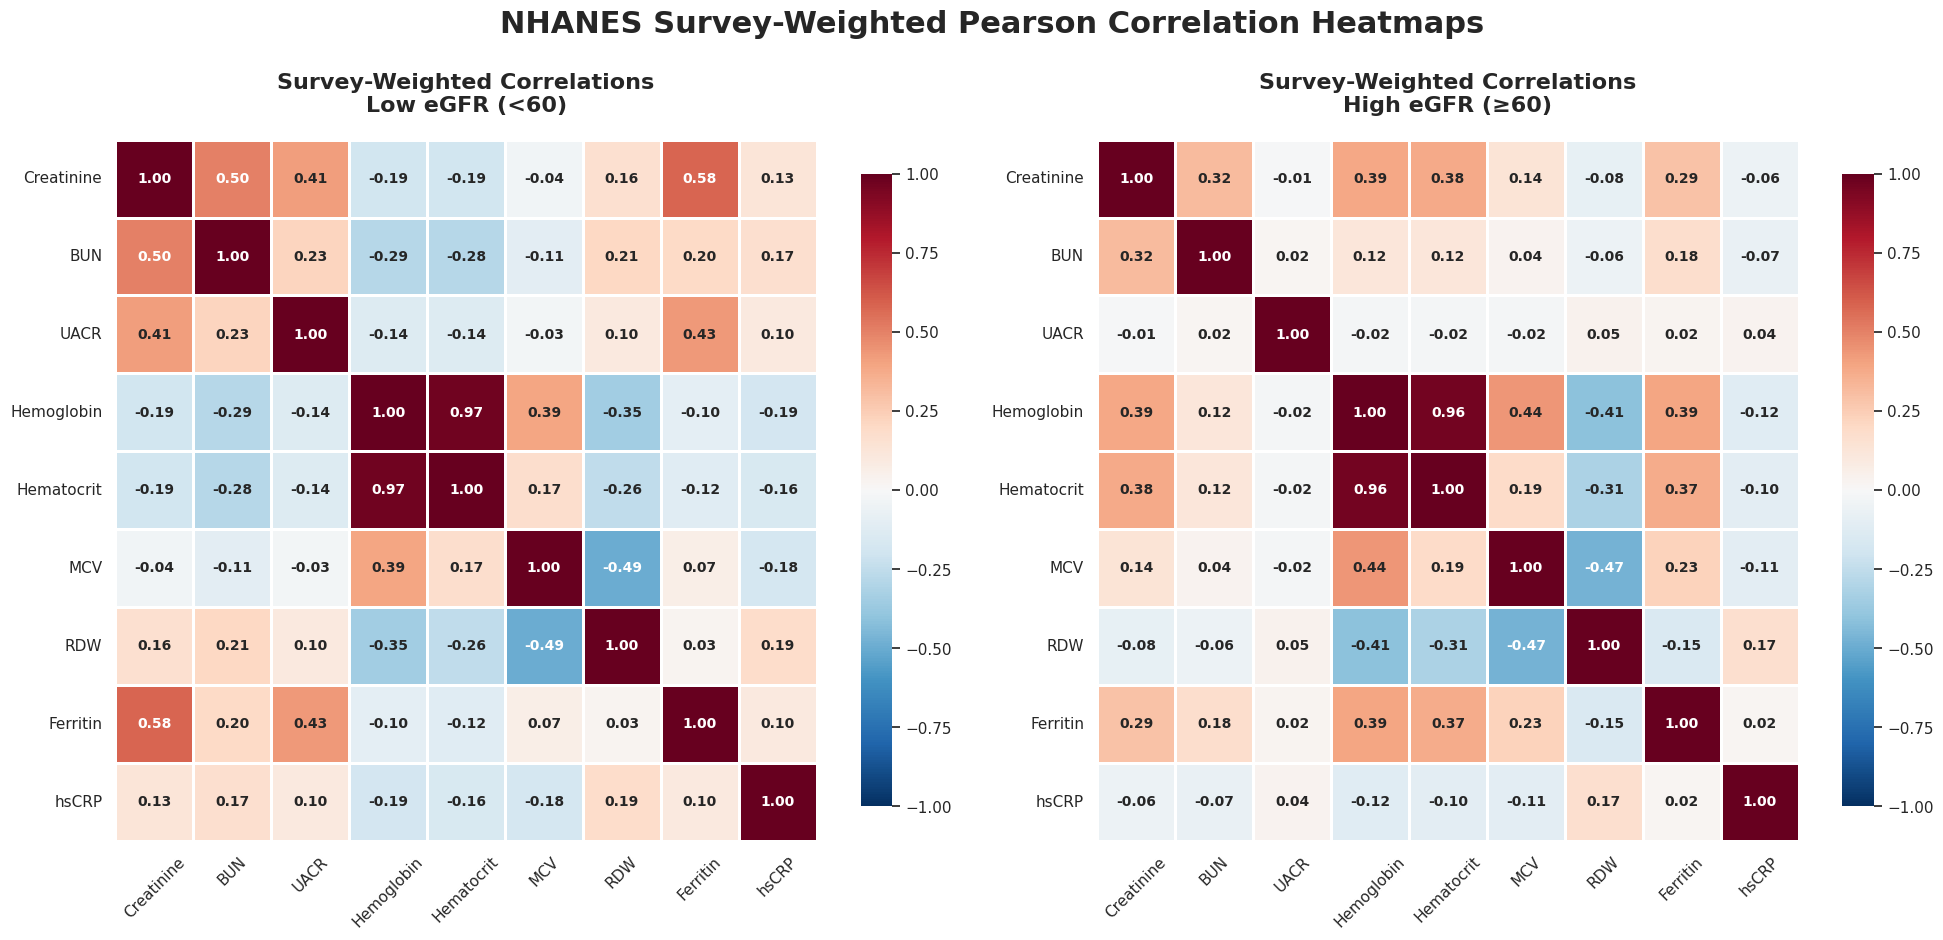

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# =====================================================
# MANUALLY ENTER YOUR CORRELATION MATRICES
# =====================================================

low_corr = pd.DataFrame([
    [1.000, 0.501, 0.415, -0.190, -0.194, -0.035, 0.162, 0.579, 0.130],
    [0.501, 1.000, 0.226, -0.289, -0.282, -0.107, 0.210, 0.197, 0.166],
    [0.415, 0.226, 1.000, -0.136, -0.138, -0.025, 0.101, 0.433, 0.101],
    [-0.190, -0.289, -0.136, 1.000, 0.973, 0.392, -0.348, -0.101, -0.186],
    [-0.194, -0.282, -0.138, 0.973, 1.000, 0.174, -0.256, -0.124, -0.157],
    [-0.035, -0.107, -0.025, 0.392, 0.174, 1.000, -0.493, 0.070, -0.178],
    [0.162, 0.210, 0.101, -0.348, -0.256, -0.493, 1.000, 0.028, 0.186],
    [0.579, 0.197, 0.433, -0.101, -0.124, 0.070, 0.028, 1.000, 0.101],
    [0.130, 0.166, 0.101, -0.186, -0.157, -0.178, 0.186, 0.101, 1.000]
])

high_corr = pd.DataFrame([
    [1.000, 0.319, -0.008, 0.385, 0.378, 0.138, -0.079, 0.294, -0.061],
    [0.319, 1.000, 0.021, 0.118, 0.121, 0.035, -0.055, 0.177, -0.074],
    [-0.008, 0.021, 1.000, -0.023, -0.020, -0.019, 0.046, 0.024, 0.037],
    [0.385, 0.118, -0.023, 1.000, 0.965, 0.438, -0.407, 0.391, -0.123],
    [0.378, 0.121, -0.020, 0.965, 1.000, 0.193, -0.314, 0.371, -0.105],
    [0.138, 0.035, -0.019, 0.438, 0.193, 1.000, -0.473, 0.232, -0.108],
    [-0.079, -0.055, 0.046, -0.407, -0.314, -0.473, 1.000, -0.150, 0.168],
    [0.294, 0.177, 0.024, 0.391, 0.371, 0.232, -0.150, 1.000, 0.023],
    [-0.061, -0.074, 0.037, -0.123, -0.105, -0.108, 0.168, 0.023, 1.000]
])

variables = [
    "Creatinine",
    "BUN",
    "UACR",
    "Hemoglobin",
    "Hematocrit",
    "MCV",
    "RDW",
    "Ferritin",
    "hsCRP"
]

low_corr.columns = variables
low_corr.index = variables

high_corr.columns = variables
high_corr.index = variables

# =====================================================
# PLOT SETTINGS
# =====================================================

sns.set_theme(style="white")

fig, axes = plt.subplots(
    1,
    2,
    figsize=(20, 9)
)

heatmap_style = dict(
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=1,
    linecolor="white",
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 10, "weight": "bold"}
)
sns.heatmap(
    low_corr,
    ax=axes[0],
    **heatmap_style
)

axes[0].set_title(
    "Survey-Weighted Correlations\nLow eGFR (<60)",
    fontsize=16,
    weight="bold",
    pad=20
)

axes[0].tick_params(axis='x', rotation=45)
axes[0].tick_params(axis='y', rotation=0)
sns.heatmap(
    high_corr,
    ax=axes[1],
    **heatmap_style
)

axes[1].set_title(
    "Survey-Weighted Correlations\nHigh eGFR (≥60)",
    fontsize=16,
    weight="bold",
    pad=20
)

axes[1].tick_params(axis='x', rotation=45)
axes[1].tick_params(axis='y', rotation=0)
fig.suptitle(
    "NHANES Survey-Weighted Pearson Correlation Heatmaps",
    fontsize=22,
    weight="bold",
    y=1.02
)

plt.tight_layout()

# SAVE HIGH QUALITY
plt.savefig(
    "weighted_heatmaps_python.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

In [ ]:
df <- read.csv("NHANES_CKD_GRAPH.csv")
df$EGFR_GROUP <- ifelse(df$EGFR < 60, "Low", "High")
table(df$EGFR_GROUP)

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

# Load data
df = pd.read_csv("NHANES_CKD_GRAPH.csv")

# Define anemia
df["ANEMIA"] = 0
df.loc[(df["RIAGENDR"] == 1) & (df["LBXHGB"] < 13), "ANEMIA"] = 1
df.loc[(df["RIAGENDR"] == 2) & (df["LBXHGB"] < 12), "ANEMIA"] = 1

# Remove unwanted columns
exclude = [
    "SEQN","SDMVSTRA","SDMVPSU","WTMEC2YR","WTMEC6YR","WTSAF2YR",
    "CYCLE","MORTSTAT","EGFR","LBXHGB","LBXHCT","ANEMIA"
]
features = [c for c in df.columns if c not in exclude]

df_ml = df[features + ["ANEMIA", "EGFR"]].dropna(subset=["ANEMIA","EGFR"])

# Split groups
groups = {
    "Healthy (eGFR >= 60)": df_ml[df_ml["EGFR"] >= 60],
    "CKD (eGFR < 60)": df_ml[df_ml["EGFR"] < 60]
}

# Models
models = {
    "LogReg": LogisticRegression(max_iter=2000),
    "RandomForest": RandomForestClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "XGBoost": XGBClassifier(eval_metric="auc"),
    "SVM": SVC(probability=True)
}

for name, data in groups.items():
    print(f"\n=== {name} ===")

    X = data[features]
    y = data["ANEMIA"]

    if y.nunique() < 2:
        print("Not enough class variation.")
        continue

    num_cols = X.select_dtypes(include=[np.number]).columns
    cat_cols = X.select_dtypes(exclude=[np.number]).columns

    preprocessor = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore")), cat_cols)
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42
    )

    for model_name, model in models.items():
        clf = make_pipeline(preprocessor, model)
        clf.fit(X_train, y_train)

        probs = clf.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probs)

        print(f"{model_name}: AUC = {auc:.4f}")

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

df = pd.read_csv("NHANES_CKD_GRAPH.csv")

df["ANEMIA"] = 0
df.loc[(df["RIAGENDR"] == 1) & (df["LBXHGB"] < 13), "ANEMIA"] = 1
df.loc[(df["RIAGENDR"] == 2) & (df["LBXHGB"] < 12), "ANEMIA"] = 1

base_exclude = [
    "SEQN", "SDMVSTRA", "SDMVPSU", "WTMEC2YR", "WTMEC6YR", "WTSAF2YR",
    "CYCLE", "MORTSTAT", "EGFR", "LBXHGB", "LBXHCT", "ANEMIA"
]

cbc_columns = [
    "LBXWBCSI", "LBXRBCSI", "LBXMCVSI", "LBXMCHSI", "LBXMC",
    "LBXRDW", "LBXPLTSI", "LBXMVP", "LBDLYMNO", "LBDMONO",
    "LBDNENO", "LBDEONO", "LBDBANO"
]
cbc_columns = [c for c in cbc_columns if c in df.columns]

features_with_cbc = [c for c in df.columns if c not in base_exclude]
features_without_cbc = [c for c in features_with_cbc if c not in cbc_columns]

df_ml = df.dropna(subset=["ANEMIA", "EGFR"]).copy()

groups = {
    "Healthy (eGFR >= 60)": df_ml[df_ml["EGFR"] >= 60],
    "CKD (eGFR < 60)": df_ml[df_ml["EGFR"] < 60]
}

feature_configs = {
    "WITH CBC Parameters": features_with_cbc,
    "WITHOUT CBC Parameters": features_without_cbc
}

models = {
    "LogReg": LogisticRegression(max_iter=2000),
    "RandomForest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric="auc", random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

for group_name, data in groups.items():
    print(f"\n{'='*50}\nPOPULATION GROUP: {group_name}\n{'='*50}")

    y = data["ANEMIA"]
    if y.nunique() < 2:
        print("Not enough class variation.")
        continue

    for config_name, feature_list in feature_configs.items():
        print(f"\n>>> EXPERIMENT: {config_name} <<<")

        X = data[feature_list]

        num_cols = X.select_dtypes(include=[np.number]).columns
        cat_cols = X.select_dtypes(exclude=[np.number]).columns

        preprocessor = ColumnTransformer([
            ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
            ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                  OneHotEncoder(handle_unknown="ignore")), cat_cols)
        ])

        for model_name, model in models.items():
            clf = make_pipeline(preprocessor, model)

            # 10-Fold CV calculation
            cv_scores = cross_val_score(clf, X, y, cv=cv_strategy, scoring="roc_auc", n_jobs=-1)

            mean_auc = np.mean(cv_scores)
            std_auc = np.std(cv_scores)

            print(f"{model_name:<15}: Mean AUC = {mean_auc:.4f} ± {std_auc:.4f}")

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Load data
df = pd.read_csv("NHANES_CKD_GRAPH.csv")

# Define anemia
df["ANEMIA"] = 0
df.loc[(df["RIAGENDR"] == 1) & (df["LBXHGB"] < 13), "ANEMIA"] = 1
df.loc[(df["RIAGENDR"] == 2) & (df["LBXHGB"] < 12), "ANEMIA"] = 1

# Remove leakage / ID columns
exclude = [
    "SEQN", "SDMVSTRA", "SDMVPSU", "WTMEC2YR", "WTMEC6YR", "WTSAF2YR",
    "CYCLE", "MORTSTAT", "EGFR", "LBXHGB", "LBXHCT", "ANEMIA","LBXWBCSI", "LBXRBCSI", "LBXMCVSI", "LBXMCHSI", "LBXMC",
    "LBXRDW", "LBXPLTSI", "LBXMVP", "LBDLYMNO", "LBDMONO",
    "LBDNENO", "LBDEONO", "LBDBANO"
]
features = [c for c in df.columns if c not in exclude]

df_ml = df[features + ["ANEMIA", "EGFR"]].dropna(subset=["ANEMIA", "EGFR"])

groups = {
    "Healthy Group (eGFR >= 60)": df_ml[df_ml["EGFR"] >= 60].copy(),
    "CKD Group (eGFR < 60)": df_ml[df_ml["EGFR"] < 60].copy()
}

def build_preprocessor(X):
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

    transformers = []
    if num_cols:
        transformers.append(("num", SimpleImputer(strategy="median"), num_cols))
    if cat_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            cat_cols
        ))

    return ColumnTransformer(transformers, sparse_threshold=0), num_cols, cat_cols

def get_feature_names(preprocessor, num_cols, cat_cols):
    names = []
    if num_cols:
        names.extend(num_cols)
    if cat_cols and "cat" in preprocessor.named_transformers_:
        ohe = preprocessor.named_transformers_["cat"].named_steps["onehot"]
        names.extend(ohe.get_feature_names_out(cat_cols).tolist())
    return names

def get_shap_matrix(explainer, X_p):
    sv = explainer.shap_values(X_p)
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.array(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return sv

for group_name, data in groups.items():
    print(f"\n=== {group_name} ===")

    X = data[features]
    y = data["ANEMIA"]

    if y.nunique() < 2:
        print("Not enough class variation.")
        continue

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42
    )

    preprocessor, num_cols, cat_cols = build_preprocessor(X_train)
    X_train_p = preprocessor.fit_transform(X_train)
    X_test_p = preprocessor.transform(X_test)

    rf = RandomForestClassifier(random_state=42)
    rf.fit(X_train_p, y_train)

    probs = rf.predict_proba(X_test_p)[:, 1]
    auc = roc_auc_score(y_test, probs)
    print(f"RandomForest AUC: {auc:.4f}")

    explainer = shap.TreeExplainer(rf)
    shap_vals = get_shap_matrix(explainer, X_test_p)

    feature_names = get_feature_names(preprocessor, num_cols, cat_cols)

    plt.figure(figsize=(10, 6))
    shap.summary_plot(
        shap_vals,
        X_test_p,
        feature_names=feature_names,
        max_display=15,
        show=False
    )
    plt.title(f"SHAP Beeswarm: {group_name}")
    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ---------------------------------------------------------
# LOAD AND SPLIT
# ---------------------------------------------------------
df = pd.read_csv("NHANES_CKD_GRAPH.csv")

exclude = ['SEQN','MORTSTAT','WTSAF2YR','WTMEC6YR','WTFOL2YR',
           'SDMVSTRA','SDMVPSU','WTMEC2YR','RIDAGEYR','RIAGENDR',
           'RIDRETH3','CYCLE','PHAFSTHR','PHAFSTMN','LBDLDLM','LBDLDLN']

features = [c for c in df.select_dtypes(include=np.number).columns
            if c not in exclude and c != 'EGFR']

low  = df[df['EGFR'] <  60][features].dropna(axis=1, thresh=int(0.8*(df['EGFR']< 60).sum()))
high = df[df['EGFR'] >= 60][features].dropna(axis=1, thresh=int(0.8*(df['EGFR']>=60).sum()))
shared = list(set(low.columns) & set(high.columns))
low, high = low[shared].dropna(), high[shared].dropna()

corr_low  = low[shared].corr(method='spearman')
corr_high = high[shared].corr(method='spearman')

diff_matrix = corr_high - corr_low
DIFF_THRESHOLD = 0.2

G_diff = nx.Graph()
G_diff.add_nodes_from(shared)

for i in range(len(shared)):
    for j in range(i+1, len(shared)):
        v1, v2 = shared[i], shared[j]
        d = diff_matrix.loc[v1, v2]
        if abs(d) >= DIFF_THRESHOLD:
            G_diff.add_edge(v1, v2, weight=abs(d), sign=np.sign(d))

# Remove isolates
G_diff.remove_nodes_from(list(nx.isolates(G_diff)))
print(f"Differential network: {len(G_diff.nodes)} nodes, {len(G_diff.edges)} edges")

# Plot
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G_diff, seed=42, k=0.5)

# Edge colors: orange = stronger in high eGFR, blue = stronger in low eGFR
edge_colors = ['#E07B39' if G_diff[u][v]['sign'] > 0 else '#4682B4'
               for u,v in G_diff.edges()]
edge_weights = [G_diff[u][v]['weight'] * 3 for u,v in G_diff.edges()]

# Node size by degree (how many rewired edges it participates in)
degree = dict(G_diff.degree())
node_sizes = [degree[n] * 300 + 200 for n in G_diff.nodes()]

nx.draw_networkx_nodes(G_diff, pos, node_size=node_sizes,
                       node_color='#2C3E50', alpha=0.85)
nx.draw_networkx_edges(G_diff, pos, edge_color=edge_colors,
                       width=edge_weights, alpha=0.6)
nx.draw_networkx_labels(G_diff, pos, font_size=8,
                        font_color='white', font_weight='bold')

plt.title("Differential Correlation Network: High vs Low eGFR\n"
          "Orange = stronger in healthy | Blue = stronger in CKD\n"
          "Node size = number of rewired relationships",
          fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.savefig("differential_network.png", dpi=300, bbox_inches='tight')
plt.show()

def rewiring_score(c_high, c_low, variables, threshold=0.2):
    scores = {}
    for var in variables:
        count = 0
        for other in variables:
            if var == other: continue
            if abs(c_high.loc[var,other] - c_low.loc[var,other]) >= threshold:
                count += 1
        scores[var] = count
    return scores

observed = rewiring_score(corr_high, corr_low, shared)

n_boot = 1000
boot_scores = {f: [] for f in shared}

for _ in range(n_boot):
    b_low  = low.sample(n=len(low),   replace=True)
    b_high = high.sample(n=len(high), replace=True)
    c_l = b_low.corr(method='spearman')
    c_h = b_high.corr(method='spearman')
    s   = rewiring_score(c_h, c_l, shared)
    for f in shared:
        boot_scores[f].append(s[f])

results = pd.DataFrame({
    'feature':   shared,
    'rewiring':  [observed[f] for f in shared],
    'ci_lower':  [np.percentile(boot_scores[f], 2.5)  for f in shared],
    'ci_upper':  [np.percentile(boot_scores[f], 97.5) for f in shared]
}).sort_values('rewiring', ascending=False)

# Significant = CI lower bound > 0
results['significant'] = results['ci_lower'] > 0

print(results.head(20))
results.to_csv("rewiring_scores.csv", index=False)

# Plot top 20
top20 = results.head(20).sort_values('rewiring')
plt.figure(figsize=(10, 8))
colors = ['#E07B39' if s else '#95a5a6' for s in top20['significant']]
plt.barh(top20['feature'], top20['rewiring'], color=colors, alpha=0.85)
plt.errorbar(top20['rewiring'], top20['feature'],
             xerr=[top20['rewiring']-top20['ci_lower'],
                   top20['ci_upper']-top20['rewiring']],
             fmt='none', color='black', capsize=3)
plt.xlabel("Rewiring Score (number of significantly changed relationships)")
plt.title("Biomarker Correlation Rewiring: High vs Low eGFR\nOrange = significant (bootstrap 95% CI > 0)")
plt.tight_layout()
plt.savefig("rewiring_scores.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# For LBXSCR specifically, show WHICH 13 relationships rewired
# This makes the creatinine hub story concrete

scr_rewired = []
for other in shared:
    if other == 'LBXSCR': continue
    d = corr_high.loc['LBXSCR', other] - corr_low.loc['LBXSCR', other]
    if abs(d) >= 0.2:
        scr_rewired.append({
            'partner': other,
            'corr_high': round(corr_high.loc['LBXSCR', other], 3),
            'corr_low':  round(corr_low.loc['LBXSCR', other], 3),
            'diff': round(d, 3)
        })

pd.DataFrame(scr_rewired).sort_values('diff', key=abs, ascending=False)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# 1. Load your dataset
df = pd.read_csv("NHANES_CKD_GRAPH.csv")

# 2. Select ONLY the core labs that have high completeness across the whole population
# This skips the sparse fasting/urine sub-samples
robust_features = [
    "LBXSCR", "LBXSBU",            # Standard Kidney Waste (Creatinine / BUN)
    "LBXHGB", "LBXHCT", "LBXMC",   # Core CBC (Hemoglobin, Hematocrit, etc.)
    "LBXSAL", "LBXSTP", "LBXSUA"   # General Chemistries (Albumin, Total Protein, Uric Acid)
]

# 3. Filter down to rows where these specific robust features + EGFR exist
columns_to_keep = robust_features + ["EGFR"]
df_clean = df[columns_to_keep].dropna().copy()

print("--- Data Recovery Verification ---")
print(f"Original dataset rows: {len(df)}")
print(f"Rows retained using robust features: {len(df_clean)}")
print(f"Features driving the t-SNE: {robust_features}")
print("----------------------------------")

# 4. Separate features and target
X_raw = df_clean[robust_features]
y_labels = np.where(df_clean["EGFR"] < 60, "Low eGFR (<60)", "High eGFR (>=60)")

# 5. Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 6. Run t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=123,
    n_iter=1000,
    init='pca',
    learning_rate='auto'
)
tsne_results = tsne.fit_transform(X_scaled)

# 7. Plotting DataFrame
df_plot = pd.DataFrame({
    "t-SNE 1": tsne_results[:, 0],
    "t-SNE 2": tsne_results[:, 1],
    "EGFR Status": y_labels
})

# 8. Render Plot
plt.figure(figsize=(10, 7))
sns.set_theme(style="ticks")

sns.scatterplot(
    x="t-SNE 1",
    y="t-SNE 2",
    hue="EGFR Status",
    alpha=0.4,  # Lowered alpha since you will now see thousands of dense points
    palette={"Low eGFR (<60)": "#E41A1C", "High eGFR (>=60)": "#377EB8"},
    data=df_plot
)

plt.title("t-SNE Map: High-Density Core Biomarkers", fontsize=14, fontweight='bold')
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
install.packages("survey")
install.packages("survival")
install.packages("dplyr")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
!pip install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 8.9 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=232e3effed4d8c062971b6949383c09297a278ce9e87c06be05a1b473ec70516
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma


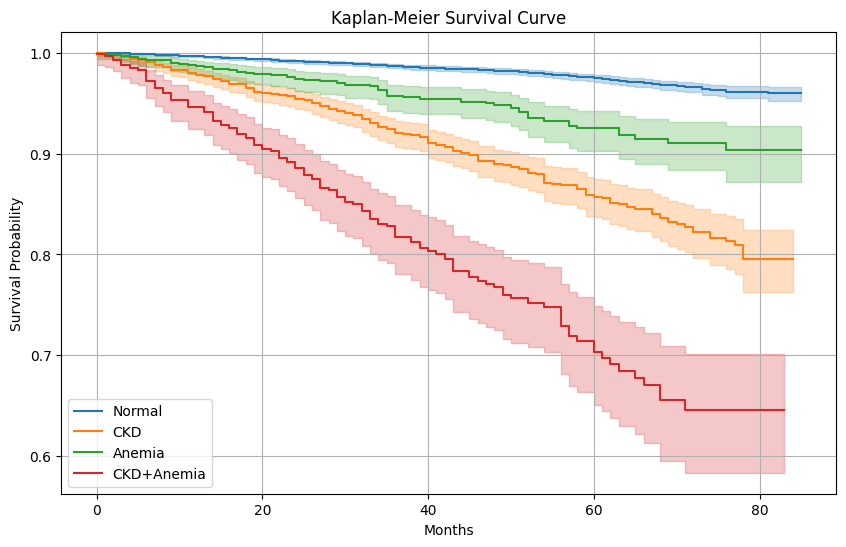


Mortality Estimates

Normal
  1-Year Mortality: 0.35%
  3-Year Mortality: 1.32%

CKD
  1-Year Mortality: 2.16%
  3-Year Mortality: 7.94%

Anemia
  1-Year Mortality: 1.35%
  3-Year Mortality: 4.30%

CKD+Anemia
  1-Year Mortality: 5.35%
  3-Year Mortality: 18.25%



In [ ]:
from lifelines import KaplanMeierFitter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# LOAD DATA
# =========================================================

df = pd.read_csv("NHANES_CKD_GRAPH.csv")

# =========================================================
# CLEAN
# =========================================================

df = df.dropna(subset=[
    "LBXSCR",
    "URXUMA",
    "URXUCR",
    "LBXHGB",
    "RIAGENDR",
    "RIDAGEYR",
    "PERMTH_EXM",
    "MORTSTAT"
])

# =========================================================
# eGFR (CKD-EPI 2021)
# =========================================================

kappa = np.where(df["RIAGENDR"] == 2, 0.7, 0.9)
alpha = np.where(df["RIAGENDR"] == 2, -0.241, -0.302)
sex_factor = np.where(df["RIAGENDR"] == 2, 1.012, 1)

df["eGFR"] = (
    142 *
    np.minimum(df["LBXSCR"] / kappa, 1) ** alpha *
    np.maximum(df["LBXSCR"] / kappa, 1) ** (-1.200) *
    (0.9938 ** df["RIDAGEYR"]) *
    sex_factor
)

# =========================================================
# UACR
# =========================================================

df["UACR"] = (df["URXUMA"] / df["URXUCR"]) * 100

# =========================================================
# CKD
# =========================================================

df["CKD"] = np.where(
    (df["eGFR"] < 60) |
    (df["UACR"] >= 30),
    1,
    0
)

# =========================================================
# ANEMIA
# =========================================================

df["ANEMIA"] = np.where(
    ((df["RIAGENDR"] == 1) & (df["LBXHGB"] < 13)) |
    ((df["RIAGENDR"] == 2) & (df["LBXHGB"] < 12)),
    1,
    0
)

# =========================================================
# GROUPS
# =========================================================

df["GROUP"] = "Normal"

df.loc[
    (df["CKD"] == 1) &
    (df["ANEMIA"] == 0),
    "GROUP"
] = "CKD"

df.loc[
    (df["CKD"] == 0) &
    (df["ANEMIA"] == 1),
    "GROUP"
] = "Anemia"

df.loc[
    (df["CKD"] == 1) &
    (df["ANEMIA"] == 1),
    "GROUP"
] = "CKD+Anemia"

# =========================================================
# KAPLAN-MEIER
# =========================================================

kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for group in ["Normal", "CKD", "Anemia", "CKD+Anemia"]:

    subset = df[df["GROUP"] == group]

    kmf.fit(
        durations=subset["PERMTH_EXM"],
        event_observed=subset["MORTSTAT"],
        label=group
    )

    kmf.plot_survival_function()

plt.title("Kaplan-Meier Survival Curve")
plt.xlabel("Months")
plt.ylabel("Survival Probability")
plt.grid(True)

plt.show()
print("\nMortality Estimates\n")

for group in ["Normal", "CKD", "Anemia", "CKD+Anemia"]:

    subset = df[df["GROUP"] == group]

    kmf.fit(
        durations=subset["PERMTH_EXM"],
        event_observed=subset["MORTSTAT"]
    )

    surv_1yr = kmf.predict(12)
    surv_3yr = kmf.predict(36)

    mort_1yr = (1 - surv_1yr) * 100
    mort_3yr = (1 - surv_3yr) * 100

    print(f"{group}")
    print(f"  1-Year Mortality: {mort_1yr:.2f}%")
    print(f"  3-Year Mortality: {mort_3yr:.2f}%\n")

In [ ]:
import pandas as pd

df = pd.read_csv("NHANES_CKD_GRAPH.csv")

print(df["PERMTH_EXM"].describe())

print(
    df["PERMTH_EXM"]
    .sort_values)

count    17131.00000
mean        47.13064
std         21.11261
min          0.00000
25%         29.00000
50%         47.00000
75%         65.00000
max         85.00000
Name: PERMTH_EXM, dtype: float64
<bound method Series.sort_values of 0        78.0
1        58.0
2        82.0
3         NaN
4         9.0
         ... 
29395    34.0
29396    30.0
29397    17.0
29398     NaN
29399    26.0
Name: PERMTH_EXM, Length: 29400, dtype: float64>


In [ ]:
df = pd.read_csv("NHANES_CKD_GRAPH.csv")

print(df["PERMTH_EXM"].describe())

count    15819.000000
mean         4.445414
std          2.825449
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max          9.000000
Name: PERMTH_EXM, dtype: float64


In [ ]:
import requests

url = "https://ftp.cdc.gov/pub/Health_Statistics/NCHS/datalinkage/linked_mortality/NHANES_2013_2014_MORT_2019_PUBLIC.dat"

txt = requests.get(url).text

line = txt.splitlines()[0]

print(line)
print(len(line))

73557         10   ..                     78 78
47


In [ ]:
import requests

url = "https://ftp.cdc.gov/pub/Health_Statistics/NCHS/datalinkage/linked_mortality/NHANES_2013_2014_MORT_2019_PUBLIC.dat"
r = requests.get(url, timeout=60)
lines = r.text.split('\n')

# Print first 3 lines with column ruler so you can see the layout
ruler = ''.join([str(i % 10) for i in range(100)])
print("POSITION:", ruler)
for line in lines[:3]:
    print("DATA:    ", line[:100])
    print("LENGTH:  ", len(line))
    print()

POSITION: 0123456789012345678901234567890123456789012345678901234567890123456789012345678901234567890123456789
DATA:     73557         10   ..                     78 78
LENGTH:   48

DATA:     73558         1100710                     58 58
LENGTH:   48

DATA:     73559         10   ..                     83 82
LENGTH:   48

